# E13-H74 - order-kernel reach on long sequences

**Author**: Konrad Jelen (kj) <br>
**Date**: 2026-10-09 <br>
**Pipeline stage**: experiment - E13 campaign, stage A (measure), registered hypothesis E13-H74 <br>

Measures the shipped OPW order gap (`docdistance.distance.opw_gap`, the read behind `structure_closeness`) on
sequences of 300 statements, where one block of 10 statements is moved by `d` positions. The ibm and
wergeland fixtures hold at most 14 statements per document, so the order axis has no long-document reading
before this notebook.

**Hypothesis under test**. At equal lengths and the shipped `σ = 1` the log-kernel of `_opw_plan`
(`src/docdistance/distance.py:145-173`) falls as `−(i−j)²/4`, so its float64 value is exactly zero beyond
about 54 positions. The registered claim is that the coupling cannot carry mass to a counterpart outside that
support, so the order gap stops growing once the block moves further than the support while it still grows
inside it.

The kernel, for `N = M` and position offset `Δ = |i − j|`:

$$\log K_{ij} = -\frac{\Delta^2}{4\sigma^2} - \log\left(\sigma\sqrt{2\pi}\right) + \frac{1}{\lambda_2}\left(\frac{\lambda_1}{(\Delta/N)^2 + 1} - D_{ij}\right)$$

with the shipped constants `λ₁ = 50`, `λ₂ = 0.1`, `σ = 1`, shifted by its global maximum before `exp`.

## Approach
1. **Kill-gate** - rebuild `K` exactly as `_opw_plan` does for `N = M = 300` and read the entries at `|i − j| = 60` - a non-zero entry falsifies the premise
2. **Replica fidelity** - the rebuilt kernel must reproduce the shipped plan bit for bit, otherwise the gate reads a different kernel
3. **Registered experiment** - 5 seeds, block of 10 moved by `d ∈ {5, 10, 20, 50, 60, 100, 200}`, shipped `opw_gap(A, A_moved)`, on a shuffled pool and repeated with statements in their original document order
4. **Acceptance bar** - Confirmed iff the median gap grows ≥ 20% from `d = 5` to `d = 50` AND changes ≤ 5% from `d = 60` to `d = 200`; Refuted if it grows ≥ 20% from 60 to 200
5. **Mechanism reading** - the same plan's cost split by row group, to locate where the gap comes from
6. **Guardrails, measured** - `V` on the 24-pair ibm panel, default-path `smd` and `order_gap` byte identity, `src/`, `tests/` and `docs/` tree hashes

## Outputs
- `reports/E13-H74-order-kernel-reach-metrics.json` - every measured number, the bar readings and the guardrail readings
- In-notebook: kill-gate table, displacement curve per seed and as medians (table and one figure), mechanism table, guardrail table, conclusions


## Environment

No GPU is used. `CUDA_VISIBLE_DEVICES` is set empty before the torch import, so the SaT segmenter and the
shipped OpenVINO INT8 mmBERT encoder both run on CPU. Every optimal-transport solve is CPU numpy and POT.

In [1]:
import os

os.environ["CUDA_VISIBLE_DEVICES"] = ""  # CPU only - no CUDA device is visible to torch
os.environ["CUDA_DEVICE_ORDER"] = "PCI_BUS_ID"
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["TRANSFORMERS_VERBOSITY"] = "error"
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
os.environ["HF_HUB_DISABLE_TELEMETRY"] = "1"

import warnings

warnings.filterwarnings("ignore")

import torch  # imported after the CPU pin; the SaT segmenter runs on it

print(f"torch {torch.__version__} | cuda visible: {torch.cuda.is_available()} | device: cpu | encoder: OpenVINO INT8")

torch 2.11.0+cu130 | cuda visible: False | device: cpu | encoder: OpenVINO INT8


## Imports

The shipped `docdistance` core and pipeline, POT, Polars for the result tables, Rich and matplotlib for the
output. `_round_to_polytope` and `_load_body` are private shipped functions, imported so the kernel replica
and the document loader are the shipped code paths.

In [2]:
%load_ext autoreload
%autoreload 2

# stdlib
import hashlib  # sha256 of the src, tests and docs trees
import json  # fixture load and metrics export
import random  # seeded for reproducibility
import struct  # exact byte comparison of float64 guardrail readings
import subprocess  # git status of src and tests
from pathlib import Path  # repository paths

# scientific
import numpy as np  # arrays, permutations, the kernel replica
import polars as pl  # result tables

# viz
import matplotlib.pyplot as plt  # the one inline figure

# console
from rich import print as rprint  # configuration render
from rich.console import Console  # tables
from rich.table import Table  # tabular output

# optimal transport and the shipped core
import ot  # POT - version reported only, every solve goes through the shipped functions
import docdistance  # version
from docdistance import DocDistance  # shipped pipeline: segmenter and encoder
from docdistance.distance import (
    OPW_LAMBDA1,  # inverse-difference-moment weight, 50
    OPW_LAMBDA2,  # entropic regularization, 0.1
    OPW_SIGMA,  # temporal-prior bandwidth, 1
    SMD_MAX,  # closeness scale, sqrt(2)
    STRUCTURE_THRESHOLD,  # shipped structural cutoff, 0.90
    _round_to_polytope,  # shipped rounding step of _opw_plan, reused by the replica
    closeness,  # distance to 0-1 closeness
    cost_matrix,  # ground cost sqrt(2 - 2cos)
    opw_gap,  # the measured quantity
    opw_plan,  # the coupling behind opw_gap, for the row-group split
    smd,  # exact Statement Mover's Distance
    verdict,  # closeness against a cutoff
)
from docdistance.pipeline import _load_body  # shipped file loader (title line removed)

console = Console(width=190)  # wide enough that no table column is truncated
print(f"imports ready | docdistance {docdistance.__version__} | POT {ot.__version__} | numpy {np.__version__} | polars {pl.__version__}")

imports ready | docdistance 1.1.5 | POT 0.9.6.post1 | numpy 2.4.6 | polars 1.42.1


## Reproducibility

One base seed. Every sequence and block start is drawn from `np.random.default_rng([SEED, arm, seed])`, so
each of the 10 sequences is reproducible on its own. The encoder is a frozen INT8 graph, the Sinkhorn loop
has a fixed iteration count and the EMD solve is exact.

In [3]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
print(f"SEED={SEED}")

SEED=42


## Configuration

Paths, the registered experiment grid, the kill-gate offset and the acceptance bar, all read from the ledger
record `E13-H74`. The bar is applied literally in the acceptance section and is not changed after any
result.

In [4]:
ROOT = Path("/home/lab/workspace/learning/projects/docdistance")

# Paths
STATEMENTS_PARQUET = ROOT / "data/interim/01-statements.parquet"  # 163 pooled statements, column `text`
IBM_SOURCE = ROOT / "data/interim/exec-summaries/ibm-ai-adoption/source/source-article.md"
WERG_SOURCE = ROOT / "data/interim/ai-society-wergeland/source/source-article.md"
FIXTURE_STATEMENTS = ROOT / "data/processed/structure-fixture/statements.json"  # summaries of both articles
SUMMARY_DIR = ROOT / "data/interim/exec-summaries/ibm-ai-adoption/summaries"  # guardrail panel only
METRICS_OUT = ROOT / "reports/E13-H74-order-kernel-reach-metrics.json"

# Registered experiment (E13-H74 record)
N = 300  # sequence length; the record asks for >= 300
N_LONG = 600  # second registered length, run only if the pool holds that many unique statements
BLOCK = 10  # statements in the moved block
DISPLACEMENTS = (5, 10, 20, 50, 60, 100, 200)  # positions the block moves
ALL_D = (0, *DISPLACEMENTS)  # d = 0 is the unmoved reference, outside the registered grid
SEEDS = (0, 1, 2, 3, 4)  # 5 seeds per length
ARMS = ("shuffled", "document-order")  # primary arm, then the control for a shuffled-pool artefact

# Kill-gate (record: kernel entries at |i - j| = 60 for N = M = 300)
GATE_OFFSET = 60
GATE_TABLE_OFFSETS = (40, 50, 53, 54, 55, 60)  # offsets shown around the predicted support edge
COST_MAX = 2.0  # largest Euclidean distance between two unit vectors - the worst admissible ground cost

# Acceptance bar (record, applied literally)
NEAR = (5, 50)  # the median gap must grow >= 20% between these displacements
FAR = (60, 200)  # and change <= 5% between these
BAR_NEAR_GROWTH = 0.20
BAR_FAR_CHANGE = 0.05
BAR_FAR_REFUTE = 0.20  # growth >= 20% between 60 and 200 refutes

# Guardrails
PANEL = [  # ibm summaries: (file, label, tier); the anchor is gold
    ("exec-summary-gold-opus-4-6.md", "gold", "gold"),
    ("exec-summary-gold-2-opus-4-6.md", "gold-2", "gold"),
    ("exec-summary-1-opus-4-6.md", "v1", "gold"),
    ("exec-summary-2-opus-4-6.md", "v2", "gold"),
    ("exec-summary-opus-4-6.md", "opus", "gold"),
    ("exec-summary-sonnet-4-6.md", "sonnet", "gold"),
    ("exec-summary-haiku-4-5.md", "haiku", "gold"),
    ("exec-summary-adv1-a-sonnet-4-6.md", "adv1-a", "adv"),
    ("exec-summary-adv1-b-sonnet-4-6.md", "adv1-b", "adv"),
    ("exec-summary-adv2-a-haiku-4-5.md", "adv2-a", "adv"),
    ("exec-summary-adv2-b-haiku-4-5.md", "adv2-b", "adv"),
]
REFERENCE = "gold"
GUARD_PAIR = ("gold", "gold-2")  # default-path byte-identity pair
GUARD_TREES = ("src", "tests", "docs")  # hashed before and after
NAIVE_ROW = {"V": 0, "margin_pts": 4.71, "dprime": 4.68, "R": 1.670, "DR": 0.0873}  # primer, OpenVINO INT8

# Figure colours - one series keeps one colour in every panel
C_SHUFFLED = "#3498DB"  # shuffled arm
C_DOCORDER = "#2ECC71"  # document-order arm
C_EDGE = "#E74C3C"  # float64 support edge of the kernel
C_BLOCK, C_PASSED, C_UNTOUCHED = "#8E44AD", "#F39C12", "#7F8C8D"  # row groups of the cost split

rprint(f"""[bold cyan]Configuration[/bold cyan]
[dim]{"─" * 60}[/dim]
[bold]Registered experiment[/bold]
  Sequence length: [yellow]{N}[/yellow] [dim](and {N_LONG} if the pool allows)[/dim]
  Moved block: [yellow]{BLOCK}[/yellow] statements, moved by d in [yellow]{DISPLACEMENTS}[/yellow] positions
  Seeds: [yellow]{SEEDS}[/yellow] per arm, arms: [cyan]{ARMS}[/cyan]
  Quantity: [cyan]docdistance.distance.opw_gap(A, A_moved)[/cyan], shipped constants
    lambda1 [yellow]{OPW_LAMBDA1}[/yellow], lambda2 [yellow]{OPW_LAMBDA2}[/yellow], sigma [yellow]{OPW_SIGMA}[/yellow]

[bold]Kill-gate[/bold]
  Kernel K of _opw_plan, N = M = [yellow]{N}[/yellow], entries at |i - j| = [yellow]{GATE_OFFSET}[/yellow]
  A non-zero entry kills the run [dim](the premise is false)[/dim]

[bold]Acceptance bar[/bold]
  Confirmed: median gap grows >= [yellow]{BAR_NEAR_GROWTH:.0%}[/yellow] from d = {NEAR[0]} to d = {NEAR[1]}
             AND changes <= [yellow]{BAR_FAR_CHANGE:.0%}[/yellow] from d = {FAR[0]} to d = {FAR[1]}
  Refuted:   median gap grows >= [yellow]{BAR_FAR_REFUTE:.0%}[/yellow] from d = {FAR[0]} to d = {FAR[1]}

[bold]Guardrails[/bold]
  V on the ibm panel [dim](6 gold x 4 adversarial = 24 pairs)[/dim], byte identity of smd and order_gap on [cyan]{GUARD_PAIR}[/cyan]
  Tree hashes before and after: [cyan]{GUARD_TREES}[/cyan]

[bold]Paths[/bold]
  Metrics: [cyan]{METRICS_OUT.relative_to(ROOT)}[/cyan]

[bold]Device[/bold]
  Using: [green]cpu[/green] [dim](OpenVINO INT8 encoder, SaT segmenter)[/dim]
""")

Configuration
────────────────────────────────────────────────────────────
Registered experiment
  Sequence length: 300 (and 600 if the pool allows)
  Moved block: 10 statements, moved by d in (5, 10, 20, 50, 60, 100, 200) positions
  Seeds: (0, 1, 2, 3, 4) per arm, arms: ('shuffled', 'document-order')
  Quantity: docdistance.distance.opw_gap(A, A_moved), shipped constants
    lambda1 50.0, lambda2 0.1, sigma 1.0

Kill-gate
  Kernel K of _opw_plan, N = M = 300, entries at |i - j| = 60
  A non-zero entry kills the run (the premise is false)

Acceptance bar
  Confirmed: median gap grows >= 20% from d = 5 to d = 50
             AND changes <= 5% from d = 60 to d = 200
  Refuted:   median gap grows >= 20% from d = 60 to d = 200

Guardrails
  V on the ibm panel (6 gold x 4 adversarial = 24 pairs), byte identity of smd and order_gap on ('gold', 'gold-2')
  Tree hashes before and after: ('src', 'tests', 'docs')

Paths
  Metrics: reports/E13-H74-order-kernel-reach-metrics.json

Device
  Using: cpu (OpenVINO INT8 encoder, SaT segmenter)

## Data loading - statement pool and one embedding pass

The pool is the registered one: the 163 statements of `01-statements.parquet`, the two source articles
segmented with the shipped SaT segmenter, and the 14 summary documents of the structure fixture. Statements
are made unique by exact text, the first occurrence kept, so every statement belongs to exactly one document.
The pool is embedded once with the shipped OpenVINO INT8 encoder and the array stays in memory - every
sequence below is an index into it.

In [5]:
dd = DocDistance()  # shipped pipeline: SaT segmenter and OpenVINO INT8 mmBERT, each loaded once

fixture = json.loads(FIXTURE_STATEMENTS.read_text())
documents: list[tuple[str, list[str]]] = [
    ("01-statements.parquet", pl.read_parquet(STATEMENTS_PARQUET).sort("statement_id")["text"].to_list()),
    ("ibm source article", dd.segmenter.split(_load_body(IBM_SOURCE))),
    ("wergeland source article", dd.segmenter.split(_load_body(WERG_SOURCE))),
]
documents += [(f"summary {key}", doc["statements"]) for key, doc in fixture.items() if doc["kind"] == "summary"]

POOL_TEXTS: list[str] = []  # unique statements, document by document, original order inside a document
DOC_INDEX: list[np.ndarray] = []  # per document, the pool indices of the statements it contributed
seen: set[str] = set()
doc_rows = []
for name, statements in documents:
    first = len(POOL_TEXTS)
    for statement in statements:
        if statement not in seen:
            seen.add(statement)
            POOL_TEXTS.append(statement)
    DOC_INDEX.append(np.arange(first, len(POOL_TEXTS)))
    doc_rows.append((name, len(statements), len(POOL_TEXTS) - first))

POOL_EMB = dd.encoder.encode(POOL_TEXTS)  # the one embedding pass, cached in memory
POOL_SIZE = len(POOL_TEXTS)
POOL_COST = cost_matrix(POOL_EMB, POOL_EMB)
POOL_COST_MAX = float(POOL_COST.max())  # largest ground cost between any two pooled statements
LONG_FEASIBLE = POOL_SIZE >= N_LONG

t = Table(title="Statement pool", header_style="bold cyan")
t.add_column("document"); t.add_column("statements", justify="right"); t.add_column("unique added", justify="right")
for name, n_all, n_new in doc_rows:
    t.add_row(name, str(n_all), str(n_new))
t.add_row("[bold]pool[/bold]", str(sum(r[1] for r in doc_rows)), f"[bold]{POOL_SIZE}[/bold]")
console.print(
    t,
    f"embedded once: shape {POOL_EMB.shape}, dtype {POOL_EMB.dtype}, row norms {np.linalg.norm(POOL_EMB, axis=1).min():.6f} to {np.linalg.norm(POOL_EMB, axis=1).max():.6f}\n"
    f"largest ground cost between two pooled statements: {POOL_COST_MAX:.4f} (SMD_MAX {SMD_MAX:.4f})\n"
    f"N = {N}: {'feasible' if POOL_SIZE >= N else 'NOT feasible'} | N = {N_LONG}: "
    f"{'feasible' if LONG_FEASIBLE else f'not feasible, the pool holds {POOL_SIZE} unique statements'}",
)

                     Statement pool                     
┏━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━┓
┃ document                 ┃ statements ┃ unique added ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━┩
│ 01-statements.parquet    │        163 │          158 │
│ ibm source article       │         70 │           52 │
│ wergeland source article │         52 │           50 │
│ summary gold             │         11 │           11 │
│ summary gold-2           │         13 │           13 │
│ summary v1               │         12 │           12 │
│ summary v2               │         12 │           11 │
│ summary opus             │         13 │           13 │
│ summary sonnet           │         11 │           11 │
│ summary haiku            │         14 │           14 │
│ summary adv1-a           │         10 │           10 │
│ summary adv1-b           │         10 │            9 │
│ summary adv2-a           │          2 │            2 │
│ summary adv2-b           │          4 │            4 │
│ summary werg-a           │         11 │            0 │
│ summary werg-b           │         13 │            2 │
│ summary werg-c           │         14 │            0 │
│ pool                     │        435 │          372 │
└──────────────────────────┴────────────┴──────────────┘
embedded once: shape (372, 768), dtype float32, row norms 1.000000 to 1.000000
largest ground cost between two pooled statements: 1.3356 (SMD_MAX 1.4142)
N = 300: feasible | N = 600: not feasible, the pool holds 372 unique statements

## Sequences and block moves

Ten sequences of 300 unique statements, five per arm. The **shuffled** arm draws 300 pool statements in
random order. The **document-order** arm permutes the 17 documents, keeps every statement in its original
position inside its document, concatenates and keeps the first 300. A block move cuts the statements at
positions `start .. start+9` and re-inserts them `d` positions later; the `d` statements it passes over each
shift 10 positions the other way, so a move by `d` displaces `d + 10` statements in total. One block start
per sequence is used for every `d`, drawn so that the largest move stays inside the sequence.

In [6]:
def move_block(n: int, start: int, d: int) -> np.ndarray:
    """Index permutation that cuts positions start..start+BLOCK-1 and re-inserts them d positions later."""
    order = np.arange(n)
    rest = np.concatenate([order[:start], order[start + BLOCK :]])
    return np.concatenate([rest[: start + d], order[start : start + BLOCK], rest[start + d :]])


def build_sequence(arm: str, rng: np.random.Generator) -> np.ndarray:
    """Pool indices of one sequence of N unique statements for the given arm."""
    if arm == "shuffled":
        return rng.permutation(POOL_SIZE)[:N]
    doc_order = rng.permutation(len(DOC_INDEX))
    return np.concatenate([DOC_INDEX[k] for k in doc_order])[:N]


SEQUENCES: dict[tuple[str, int], tuple[np.ndarray, int]] = {}  # (arm, seed) -> (pool indices, block start)
for arm_id, arm in enumerate(ARMS):
    for seed in SEEDS:
        rng = np.random.default_rng([SEED, arm_id, seed])
        idx = build_sequence(arm, rng)
        start = int(rng.integers(0, N - BLOCK - max(DISPLACEMENTS) + 1))
        SEQUENCES[(arm, seed)] = (idx, start)
SEQ_EMB = {key: POOL_EMB[idx] for key, (idx, _) in SEQUENCES.items()}

# the move does what the text above says, checked on every sequence and displacement
moves_ok = True
for (arm, seed), (idx, start) in SEQUENCES.items():
    moves_ok &= len(set(idx.tolist())) == N
    for d in ALL_D:
        perm = move_block(N, start, d)
        new_pos = np.argsort(perm)  # new_pos[a] = position of original statement a after the move
        shift = new_pos - np.arange(N)
        moves_ok &= bool(np.array_equal(np.sort(perm), np.arange(N)))
        moves_ok &= bool((shift[start : start + BLOCK] == d).all())
        moves_ok &= bool((shift[start + BLOCK : start + BLOCK + d] == -BLOCK).all()) if d else True
        moves_ok &= int((shift != 0).sum()) == (d + BLOCK if d else 0)

t = Table(title=f"Sequences - N = {N}, block of {BLOCK}", header_style="bold cyan")
for c in ("arm", "seed", "block start", "mean ground cost of adjacent statements"):
    t.add_column(c, justify="left" if c == "arm" else "right")
ADJ_COST = {}
for (arm, seed), (idx, start) in SEQUENCES.items():
    ADJ_COST[(arm, seed)] = float(POOL_COST[idx[:-1], idx[1:]].mean())
    t.add_row(arm, str(seed), str(start), f"{ADJ_COST[(arm, seed)]:.4f}")
console.print(t, f"\nevery move is a permutation that shifts the block by d and the d passed-over statements by -{BLOCK}: {moves_ok}")

                        Sequences - N = 300, block of 10                         
┏━━━━━━━━━━━━━━━━┳━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ arm            ┃ seed ┃ block start ┃ mean ground cost of adjacent statements ┃
┡━━━━━━━━━━━━━━━━╇━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ shuffled       │    0 │          29 │                                  0.6195 │
│ shuffled       │    1 │          14 │                                  0.6464 │
│ shuffled       │    2 │          58 │                                  0.6277 │
│ shuffled       │    3 │          48 │                                  0.6197 │
│ shuffled       │    4 │          48 │                                  0.6456 │
│ document-order │    0 │          46 │                                  0.5881 │
│ document-order │    1 │          90 │                                  0.5736 │
│ document-order │    2 │          21 │                                  0.5512 │
│ document-order │    3 │          24 │                                  0.5977 │
│ document-order │    4 │          55 │                                  0.5697 │
└────────────────┴──────┴─────────────┴─────────────────────────────────────────┘

every move is a permutation that shifts the block by d and the d passed-over statements by -10: True

## Guardrail baseline - tree hashes and default-path reads

Recorded before any measurement so the guardrail section can compare exactly. The 11 ibm summaries are
segmented and embedded through the shipped `DocDistance.embed`, the panel distances to the gold anchor and
the default-path `smd` and `opw_gap` of one pair are stored as bytes, and the `src/`, `tests/` and `docs/`
trees are hashed.

In [7]:
def tree_sha256(rel: str) -> str:
    """One sha256 over the path and bytes of every file under a directory; caches and archives are skipped."""
    digest = hashlib.sha256()
    skip = {"__pycache__", ".ipynb_checkpoints", "@archive"}
    for dirpath, dirnames, filenames in os.walk(ROOT / rel):
        dirnames[:] = sorted(name for name in dirnames if name not in skip)
        for filename in sorted(filenames):
            path = Path(dirpath) / filename
            digest.update(str(path.relative_to(ROOT)).encode())
            digest.update(path.read_bytes())
    return digest.hexdigest()


def as_bytes(values: np.ndarray) -> bytes:
    """Little-endian float64 bytes of a reading vector, for exact comparison."""
    return struct.pack(f"<{len(values)}d", *values)


PANEL_EMB = {label: dd.embed(SUMMARY_DIR / fname) for fname, label, _ in PANEL}
NONREF = [label for _, label, _ in PANEL if label != REFERENCE]
GOLD = [label for _, label, tier in PANEL if tier == "gold" and label != REFERENCE]
ADV = [label for _, label, tier in PANEL if tier == "adv"]

gx, gy = PANEL_EMB[GUARD_PAIR[0]], PANEL_EMB[GUARD_PAIR[1]]
panel_before = np.array([smd(PANEL_EMB[label], PANEL_EMB[REFERENCE]) for label in NONREF])
guard_before = np.array([smd(gx, gy), opw_gap(gx, gy)])
trees_before = {rel: tree_sha256(rel) for rel in GUARD_TREES}

print(
    f"panel: {len(PANEL)} documents, {sum(len(e) for e in PANEL_EMB.values())} statements, {len(GOLD)} gold x {len(ADV)} adversarial pairs\n"
    f"default path on {GUARD_PAIR}: smd={float(guard_before[0])!r}  order_gap={float(guard_before[1])!r}\n"
    f"bytes: {as_bytes(guard_before).hex()}\n"
    + "\n".join(f"sha256 {rel}/: {digest[:16]}" for rel, digest in trees_before.items())
)

panel: 11 documents, 98 statements, 6 gold x 4 adversarial pairs
default path on ('gold', 'gold-2'): smd=0.22648980232576527  order_gap=0.14508837947471193
bytes: eeeeee2a9efdcc3faecf6f8a4192c23f
sha256 src/: f0e13add3de29ff3
sha256 tests/: 00ea6c7799307adb
sha256 docs/: 46241ace1c95a621


## Kill-gate - the kernel at |i − j| = 60

The kernel `K` is rebuilt with a line-for-line replica of `_opw_plan` (`distance.py:159-167`) and read at
position offset 60 for `N = M = 300`. Three readings: the kernel at zero ground cost, the kernel of every
ground-cost matrix this experiment solves (10 sequences, each against itself and against its 7 block moves),
and an upper bound that holds for every admissible ground cost. The replica is checked against the shipped
plan with `np.array_equal`, which also serves as the harness check - the record names no other sanity check.

The bound: an entry at offset 60 is largest when its own ground cost is 0 and the kernel maximum is as low
as possible. The maximum is at least a diagonal entry, whose ground cost is at most 2 (unit vectors), so

$$\log K_{60} \le \log K_{60}\big|_{D = 0} + \frac{2}{\lambda_2}$$

In [8]:
def opw_kernel(D: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    """Replica of `_opw_plan` lines 159-167, shipped constants: the Sinkhorn kernel K and its shifted log."""
    n_rows, n_cols = D.shape
    i = (np.arange(1, n_rows + 1) / n_rows)[:, None]
    j = (np.arange(1, n_cols + 1) / n_cols)[None, :]
    mid = np.abs(i - j) / np.sqrt(1 / n_rows**2 + 1 / n_cols**2)
    logP = -(mid**2) / (2 * OPW_SIGMA**2) - np.log(OPW_SIGMA * np.sqrt(2 * np.pi))
    S = OPW_LAMBDA1 / ((i - j) ** 2 + 1)
    logK = logP + (S - D) / OPW_LAMBDA2
    logK = logK - logK.max()
    return np.exp(logK), logK


def opw_plan_replica(D: np.ndarray, iters: int = 100) -> np.ndarray:
    """Replica of `_opw_plan` lines 168-173 on the replica kernel; must equal the shipped plan bit for bit."""
    K, _ = opw_kernel(D)
    n_rows, n_cols = D.shape
    a, b = np.full(n_rows, 1.0 / n_rows), np.full(n_cols, 1.0 / n_cols)
    u = np.ones(n_rows) / n_rows
    for _ in range(iters):
        v = b / (K.T @ u + 1e-300)
        u = a / (K @ v + 1e-300)
    return _round_to_polytope(u[:, None] * K * v[None, :], a, b)


OFFSET = np.abs(np.arange(N)[:, None] - np.arange(N)[None, :])  # |i - j| in positions
AT = {off: OFFSET == off for off in GATE_TABLE_OFFSETS}

K0, logK0 = opw_kernel(np.zeros((N, N)))  # zero ground cost: the kernel of position alone

measured_nonzero = dict.fromkeys(GATE_TABLE_OFFSETS, 0)
measured_max_log = dict.fromkeys(GATE_TABLE_OFFSETS, -np.inf)
measured_widest, replica_identical, n_kernels = 0, True, 0
for (arm, seed), (idx, start) in SEQUENCES.items():
    A = SEQ_EMB[(arm, seed)]
    for d in ALL_D:
        B = A[move_block(N, start, d)]
        D = cost_matrix(A, B)
        K, logK = opw_kernel(D)
        for off in GATE_TABLE_OFFSETS:
            measured_nonzero[off] += int((K[AT[off]] != 0).sum())
            measured_max_log[off] = max(measured_max_log[off], float(logK[AT[off]].max()))
        measured_widest = max(measured_widest, int(OFFSET[K != 0].max()))
        replica_identical &= bool(np.array_equal(opw_plan_replica(D), opw_plan(A, B)))
        n_kernels += 1

GATE_ENTRIES = int(AT[GATE_OFFSET].sum())  # entries at the gate offset in one kernel
GATE_NONZERO_ZERO_COST = int((K0[AT[GATE_OFFSET]] != 0).sum())
GATE_NONZERO_MEASURED = measured_nonzero[GATE_OFFSET]
GATE_LOG_ZERO_COST = float(logK0[AT[GATE_OFFSET]].max())
GATE_LOG_BOUND = GATE_LOG_ZERO_COST + COST_MAX / OPW_LAMBDA2  # holds for every admissible ground cost
GATE_BOUND_VALUE = float(np.exp(GATE_LOG_BOUND))
WIDEST_ZERO_COST = int(OFFSET[K0 != 0].max())
LOG_SMALLEST_FLOAT = float(np.log(np.nextafter(0.0, 1.0)))
KILL_GATE_PASSED = GATE_NONZERO_ZERO_COST == 0 and GATE_NONZERO_MEASURED == 0  # the registered gate, literal

t = Table(title=f"Kernel K of _opw_plan by position offset, N = M = {N}", header_style="bold cyan")
for c in ("|i - j|", "entries per kernel", "non-zero, zero cost", "largest K, zero cost", "shifted log K, zero cost",
          f"non-zero, {n_kernels} measured kernels", "largest shifted log K, measured"):
    t.add_column(c, justify="right")
for off in GATE_TABLE_OFFSETS:
    t.add_row(str(off), str(int(AT[off].sum())), str(int((K0[AT[off]] != 0).sum())), f"{K0[AT[off]].max():.3e}",
              f"{logK0[AT[off]].max():.2f}", f"{measured_nonzero[off]} of {n_kernels * int(AT[off].sum())}",
              f"{measured_max_log[off]:.2f}", style="bold" if off == GATE_OFFSET else None)
console.print(
    t,
    f"\nfloat64: log of the smallest positive value {LOG_SMALLEST_FLOAT:.2f}; np.exp(-745.13) = {float(np.exp(-745.13))!r}, np.exp(-745.14) = {float(np.exp(-745.14))!r}\n"
    f"widest offset holding a non-zero entry: {WIDEST_ZERO_COST} at zero ground cost, {measured_widest} over the {n_kernels} measured kernels\n"
    f"upper bound of shifted log K at |i - j| = {GATE_OFFSET} for every ground cost <= {COST_MAX}: {GATE_LOG_BOUND:.2f} -> exp = {GATE_BOUND_VALUE!r}\n"
    f"replica plan == shipped opw_plan on all {n_kernels} ground-cost matrices (np.array_equal): {replica_identical}\n"
    f"entries at |i - j| = {GATE_OFFSET}: non-zero {GATE_NONZERO_ZERO_COST} of {GATE_ENTRIES} at zero cost, "
    f"{GATE_NONZERO_MEASURED} of {n_kernels * GATE_ENTRIES} measured\n"
    f"[bold {'green' if KILL_GATE_PASSED else 'red'}]KILL-GATE: "
    f"{'PASSED - every entry at offset 60 is exactly 0.0, the premise holds' if KILL_GATE_PASSED else 'FIRED - a non-zero entry at offset 60, the premise is false'}[/]",
)

                                                          Kernel K of _opw_plan by position offset, N = M = 300                                                           
┏━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ |i - j| ┃ entries per kernel ┃ non-zero, zero cost ┃ largest K, zero cost ┃ shifted log K, zero cost ┃ non-zero, 80 measured kernels ┃ largest shifted log K, measured ┃
┡━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│      40 │                520 │                 520 │           3.085e-178 │                  -408.73 │                41600 of 41600 │                         -409.87 │
│      50 │                500 │                 500 │           4.979e-278 │                  -638.51 │                40000 of 40000 │                         -638.51 │
│      53 │                494 │                 494 │           2.782e-312 │                  -717.38 │                39520 of 39520 │                         -718.29 │
│      54 │                492 │                 492 │           4.941e-324 │                  -744.69 │                    0 of 39360 │                         -746.32 │
│      55 │                490 │                   0 │            0.000e+00 │                  -772.51 │                    0 of 39200 │                         -773.65 │
│      60 │                480 │                   0 │            0.000e+00 │                  -919.23 │                    0 of 38400 │                         -919.23 │
└─────────┴────────────────────┴─────────────────────┴──────────────────────┴──────────────────────────┴───────────────────────────────┴─────────────────────────────────┘

float64: log of the smallest positive value -744.44; np.exp(-745.13) = 5e-324, np.exp(-745.14) = 0.0
widest offset holding a non-zero entry: 54 at zero ground cost, 53 over the 80 measured kernels
upper bound of shifted log K at |i - j| = 60 for every ground cost <= 2.0: -899.23 -> exp = 0.0
replica plan == shipped opw_plan on all 80 ground-cost matrices (np.array_equal): True
entries at |i - j| = 60: non-zero 0 of 480 at zero cost, 0 of 38400 measured
KILL-GATE: PASSED - every entry at offset 60 is exactly 0.0, the premise holds

## Registered experiment - block-move sweep

For each of the 10 sequences and each displacement the shipped `opw_gap(A, A_moved)` is read. The same call
also reads the shipped coupling `opw_plan(A, A_moved)` and splits its cost `Σ Pᵢⱼ·Dᵢⱼ` by row group: the 10
block rows, the `d` passed-over rows and the untouched rows. `own` is the share of a row's mass that the
coupling places on the row's own statement at its new position. The split is checked to add up to the shipped
gap exactly.

In [9]:
def measure(A: np.ndarray, start: int, d: int) -> dict:
    """Shipped `opw_gap` for one block move, and the cost of the same coupling split by row group."""
    perm = move_block(N, start, d)
    B = A[perm]
    D = cost_matrix(A, B)
    P = opw_plan(A, B)
    content = smd(A, B)
    gap = opw_gap(A, B)
    row_cost = (P * D).sum(1)
    own = P[np.arange(N), np.argsort(perm)] * N  # share of each row's mass placed on its own statement
    block, passed = slice(start, start + BLOCK), slice(start + BLOCK, start + BLOCK + d)
    cost_block, cost_passed = float(row_cost[block].sum()), float(row_cost[passed].sum())
    return {
        "d": d,
        "displaced": d + BLOCK if d else 0,
        "gap": gap,
        "smd": content,
        "cost_block": cost_block,
        "cost_passed": cost_passed,
        "cost_untouched": float(row_cost.sum()) - cost_block - cost_passed,
        "own_block": float(own[block].mean()),
        "own_passed": float(own[passed].mean()) if d else None,
        "split_exact": bool(max(0.0, float((P * D).sum()) - content) == gap),
    }


rows = []
for (arm, seed), (_, start) in SEQUENCES.items():
    for d in ALL_D:
        rows.append({"arm": arm, "seed": seed, "start": start} | measure(SEQ_EMB[(arm, seed)], start, d))
sweep_df = pl.DataFrame(rows)
print(f"{sweep_df.height} solves: {len(ARMS)} arms x {len(SEEDS)} seeds x {len(ALL_D)} displacements (d = 0 is the unmoved reference)")

80 solves: 2 arms x 5 seeds x 8 displacements (d = 0 is the unmoved reference)


## Displacement curve - per seed and as medians

The order gap at every displacement, one column per seed and the median over the 5 seeds, for each arm. The
`d = 0` row is the unmoved pair `opw_gap(A, A)`, the floor the curve starts from; it is outside the
registered grid and enters no bar.

In [10]:
GAPS = {arm: {d: sweep_df.filter((pl.col("arm") == arm) & (pl.col("d") == d)).sort("seed")["gap"].to_list()
              for d in ALL_D} for arm in ARMS}
MEDIAN = {arm: {d: float(np.median(gaps)) for d, gaps in GAPS[arm].items()} for arm in ARMS}
CLOSENESS = {arm: {d: closeness(MEDIAN[arm][d]) for d in ALL_D} for arm in ARMS}  # shipped 0-1 readout of the gap
SPLIT_EXACT = bool(sweep_df["split_exact"].all())
SMD_MAX_SEEN = float(sweep_df["smd"].max())

tables = []
for arm in ARMS:
    t = Table(title=f"Order gap by displacement - {arm} arm, N = {N}, block of {BLOCK}", header_style="bold cyan")
    t.add_column("d", justify="right"); t.add_column("displaced statements", justify="right")
    for seed in SEEDS:
        t.add_column(f"seed {seed}", justify="right")
    t.add_column("median", justify="right", style="bold"); t.add_column("x median at d = 5", justify="right")
    t.add_column("structure_closeness of the median", justify="right"); t.add_column(f"shipped verdict at {STRUCTURE_THRESHOLD}")
    for d in ALL_D:
        t.add_row(str(d), str(d + BLOCK if d else 0), *[f"{g:.5f}" for g in GAPS[arm][d]],
                  f"{MEDIAN[arm][d]:.5f}", f"{MEDIAN[arm][d] / MEDIAN[arm][5]:.2f}", f"{CLOSENESS[arm][d]:.4f}",
                  verdict(CLOSENESS[arm][d], STRUCTURE_THRESHOLD), style="dim" if d == 0 else None)
    tables.append(t)
console.print(
    *tables,
    f"\nrow-group split adds up to the shipped opw_gap exactly on every solve: {SPLIT_EXACT}\n"
    f"content component smd(A, A_moved), largest over all solves: {SMD_MAX_SEEN:.6f} (same statements, so only float noise of the ground cost)",
)

                                                      Order gap by displacement - shuffled arm, N = 300, block of 10                                                       
┏━━━━━┳━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┓
┃   d ┃ displaced statements ┃  seed 0 ┃  seed 1 ┃  seed 2 ┃  seed 3 ┃  seed 4 ┃  median ┃ x median at d = 5 ┃ structure_closeness of the median ┃ shipped verdict at 0.9 ┃
┡━━━━━╇━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━┩
│   0 │                    0 │ 0.00655 │ 0.00585 │ 0.00663 │ 0.00694 │ 0.00616 │ 0.00655 │              0.20 │                            0.9954 │ similar                │
│   5 │                   15 │ 0.03385 │ 0.03072 │ 0.03228 │ 0.03229 │ 0.02981 │ 0.03228 │              1.00 │                            0.9772 │ similar                │
│  10 │                   20 │ 0.04861 │ 0.04706 │ 0.04669 │ 0.04710 │ 0.04086 │ 0.04706 │              1.46 │                            0.9667 │ similar                │
│  20 │                   30 │ 0.06838 │ 0.06501 │ 0.06386 │ 0.06726 │ 0.06145 │ 0.06501 │              2.01 │                            0.9540 │ similar                │
│  50 │                   60 │ 0.12537 │ 0.12338 │ 0.12482 │ 0.12512 │ 0.12048 │ 0.12482 │              3.87 │                            0.9117 │ similar                │
│  60 │                   70 │ 0.14200 │ 0.14548 │ 0.14540 │ 0.14324 │ 0.14215 │ 0.14324 │              4.44 │                            0.8987 │ not similar            │
│ 100 │                  110 │ 0.21933 │ 0.22269 │ 0.22578 │ 0.22110 │ 0.22091 │ 0.22110 │              6.85 │                            0.8437 │ not similar            │
│ 200 │                  210 │ 0.41615 │ 0.42295 │ 0.41153 │ 0.39928 │ 0.41617 │ 0.41615 │             12.89 │                            0.7057 │ not similar            │
└─────┴──────────────────────┴─────────┴─────────┴─────────┴─────────┴─────────┴─────────┴───────────────────┴───────────────────────────────────┴────────────────────────┘
                                                   Order gap by displacement - document-order arm, N = 300, block of 10                                                    
┏━━━━━┳━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┓
┃   d ┃ displaced statements ┃  seed 0 ┃  seed 1 ┃  seed 2 ┃  seed 3 ┃  seed 4 ┃  median ┃ x median at d = 5 ┃ structure_closeness of the median ┃ shipped verdict at 0.9 ┃
┡━━━━━╇━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━┩
│   0 │                    0 │ 0.00935 │ 0.00995 │ 0.01141 │ 0.00922 │ 0.01051 │ 0.00995 │              0.32 │                            0.9930 │ similar                │
│   5 │                   15 │ 0.03671 │ 0.03336 │ 0.02989 │ 0.02984 │ 0.03064 │ 0.03064 │              1.00 │                            0.9783 │ similar                │
│  10 │                   20 │ 0.05186 │ 0.04447 │ 0.04026 │ 0.04368 │ 0.05162 │ 0.04447 │              1.45 │                            0.9686 │ similar                │
│  20 │                   30 │ 0.06912 │ 0.06727 │ 0.06361 │ 0.06648 │ 0.06816 │ 0.06727 │              2.20 │                            0.9524 │ similar                │
│  50 │                   60 │ 0.13305 │ 0.12966 │ 0.12262 │ 0.11984 │ 0.12718 │ 0.12718 │              4.15 │                            0.9101 │ similar                │
│  60 │                   70 │ 0.15110 │ 0.14960 │ 0.13894 │ 0.14584 │ 0.14201 │ 0.14584 │              4.76 │                            0.8969 │ not similar            │
│ 100 │                  110 │ 0.22176 │ 0.2

## Acceptance bar

The registered bar, applied literally to the median order gap of the primary (shuffled) arm. The same two
readings are shown for the document-order control and per seed, so that a single sequence cannot carry the
verdict.

$$\text{growth}_{5 \to 50} = \frac{\tilde g(50)}{\tilde g(5)} - 1 \qquad \text{change}_{60 \to 200} = \frac{\tilde g(200)}{\tilde g(60)} - 1$$

where `g̃(d)` is the median over the 5 seeds.

In [11]:
def relative_change(low: float, high: float) -> float:
    """Relative change from the gap at the smaller displacement to the gap at the larger one."""
    return high / low - 1.0


BAR = {}
for arm in ARMS:
    near_seed = [relative_change(a, b) for a, b in zip(GAPS[arm][NEAR[0]], GAPS[arm][NEAR[1]])]
    far_seed = [relative_change(a, b) for a, b in zip(GAPS[arm][FAR[0]], GAPS[arm][FAR[1]])]
    BAR[arm] = {
        "near_growth": relative_change(MEDIAN[arm][NEAR[0]], MEDIAN[arm][NEAR[1]]),
        "far_change": relative_change(MEDIAN[arm][FAR[0]], MEDIAN[arm][FAR[1]]),
        "near_per_seed": near_seed,
        "far_per_seed": far_seed,
    }

primary = BAR[ARMS[0]]
NEAR_MET = bool(primary["near_growth"] >= BAR_NEAR_GROWTH)
FAR_FLAT_MET = bool(abs(primary["far_change"]) <= BAR_FAR_CHANGE)
CONFIRMED = bool(KILL_GATE_PASSED and NEAR_MET and FAR_FLAT_MET)
REFUTED = bool(KILL_GATE_PASSED and primary["far_change"] >= BAR_FAR_REFUTE)
CONTROL_AGREES = bool((BAR[ARMS[1]]["far_change"] >= BAR_FAR_REFUTE) == REFUTED
                      and (BAR[ARMS[1]]["near_growth"] >= BAR_NEAR_GROWTH) == NEAR_MET)
SEEDS_FAR_GROWING = sum(1 for arm in ARMS for value in BAR[arm]["far_per_seed"] if value >= BAR_FAR_REFUTE)
VERDICT = ("Killed-at-gate" if not KILL_GATE_PASSED else "Confirmed" if CONFIRMED
           else "Refuted" if REFUTED else "neither branch")

t = Table(title="Registered bar - median order gap", header_style="bold cyan")
for col in ("arm", f"median d = {NEAR[0]}", f"median d = {NEAR[1]}", f"growth {NEAR[0]} → {NEAR[1]}",
            f"per seed {NEAR[0]} → {NEAR[1]}, min to max", f"median d = {FAR[0]}", f"median d = {FAR[1]}",
            f"change {FAR[0]} → {FAR[1]}", f"per seed {FAR[0]} → {FAR[1]}, min to max"):
    t.add_column(col, justify="left" if col == "arm" else "right")
for arm in ARMS:
    b = BAR[arm]
    t.add_row(arm, f"{MEDIAN[arm][NEAR[0]]:.5f}", f"{MEDIAN[arm][NEAR[1]]:.5f}", f"{b['near_growth']:+.1%}",
              f"{min(b['near_per_seed']):+.1%} to {max(b['near_per_seed']):+.1%}",
              f"{MEDIAN[arm][FAR[0]]:.5f}", f"{MEDIAN[arm][FAR[1]]:.5f}", f"{b['far_change']:+.1%}",
              f"{min(b['far_per_seed']):+.1%} to {max(b['far_per_seed']):+.1%}")
clauses = Table(title=f"Clauses, primary arm ({ARMS[0]})", header_style="bold cyan")
for col in ("clause", "requirement", "reading", "met"):
    clauses.add_column(col)
clauses.add_row("growth inside the band", f"growth {NEAR[0]} → {NEAR[1]} >= {BAR_NEAR_GROWTH:.0%}", f"{primary['near_growth']:+.1%}", "yes" if NEAR_MET else "no")
clauses.add_row("flat beyond the band", f"|change {FAR[0]} → {FAR[1]}| <= {BAR_FAR_CHANGE:.0%}", f"{primary['far_change']:+.1%}", "yes" if FAR_FLAT_MET else "no")
clauses.add_row("refutation", f"growth {FAR[0]} → {FAR[1]} >= {BAR_FAR_REFUTE:.0%}", f"{primary['far_change']:+.1%}", "yes" if REFUTED else "no")
console.print(
    t, clauses,
    f"\nsequences whose own gap grows >= {BAR_FAR_REFUTE:.0%} from d = {FAR[0]} to d = {FAR[1]}: {SEEDS_FAR_GROWING} of {len(ARMS) * len(SEEDS)}\n"
    f"document-order control gives the same reading on both clauses: {CONTROL_AGREES}\n"
    f"[bold {'green' if VERDICT == 'Confirmed' else 'red'}]VERDICT: {VERDICT}[/]",
)

                                                                        Registered bar - median order gap                                                                         
┏━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ arm            ┃ median d = 5 ┃ median d = 50 ┃ growth 5 → 50 ┃ per seed 5 → 50, min to max ┃ median d = 60 ┃ median d = 200 ┃ change 60 → 200 ┃ per seed 60 → 200, min to max ┃
┡━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ shuffled       │      0.03228 │       0.12482 │       +286.6% │          +270.4% to +304.1% │       0.14324 │        0.41615 │         +190.5% │            +178.8% to +193.1% │
│ document-order │      0.03064 │       0.12718 │       +315.1% │          +262.4% to +315.1% │       0.14584 │        0.42098 │         +188.7% │            +166.0% to +188.7% │
└────────────────┴──────────────┴───────────────┴───────────────┴─────────────────────────────┴───────────────┴────────────────┴─────────────────┴───────────────────────────────┘
                  Clauses, primary arm (shuffled)                   
┏━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━┳━━━━━┓
┃ clause                 ┃ requirement             ┃ reading ┃ met ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━╇━━━━━┩
│ growth inside the band │ growth 5 → 50 >= 20%    │ +286.6% │ yes │
│ flat beyond the band   │ |change 60 → 200| <= 5% │ +190.5% │ no  │
│ refutation             │ growth 60 → 200 >= 20%  │ +190.5% │ yes │
└────────────────────────┴─────────────────────────┴─────────┴─────┘

sequences whose own gap grows >= 20% from d = 60 to d = 200: 10 of 10
document-order control gives the same reading on both clauses: True
VERDICT: Refuted

## Mechanism reading - where the gap comes from

The bar reading raises one question: the kernel is zero beyond the support edge, yet the gap keeps growing.
Two readings answer it. First, the cost of the coupling split by row group, as medians over the 5 seeds. Second,
the cost the kernel itself puts on carrying one unit of mass `Δ` positions at zero ground cost,

$$\text{pen}(\Delta) = -\lambda_2 \log K_{\Delta}\big|_{D = 0} = \frac{\lambda_2 \Delta^2}{4\sigma^2} + \lambda_1\left(1 - \frac{1}{(\Delta/N)^2 + 1}\right)$$

read from the replica kernel and compared with the largest ground cost between any two pooled statements. Where
`pen(Δ)` exceeds that cost, matching a displaced statement to itself costs more in the linear part of the
Sinkhorn objective than matching it to any statement that sits in its old position.

In [12]:
mech = (
    sweep_df.filter(pl.col("d") > 0)
    .with_columns(((pl.col("cost_block") + pl.col("cost_passed")) * N / pl.col("displaced")).alias("cost_per_displaced"))
    .group_by(["arm", "d"])
    .agg([pl.col(name).median() for name in ("gap", "cost_block", "cost_passed", "cost_untouched", "own_block", "own_passed", "cost_per_displaced")])
)
MECH = {arm: {row["d"]: row for row in mech.filter(pl.col("arm") == arm).sort("d").iter_rows(named=True)} for arm in ARMS}

FIT = {}
for arm in ARMS:
    sub = sweep_df.filter((pl.col("arm") == arm) & (pl.col("d") > 0))
    x, y = (sub["displaced"] / N).to_numpy(), sub["gap"].to_numpy()
    slope, intercept = np.polyfit(x, y, 1)
    FIT[arm] = {"slope": float(slope), "intercept": float(intercept),
                "r2": float(1 - ((y - (slope * x + intercept)) ** 2).sum() / ((y - y.mean()) ** 2).sum())}

t = Table(title="Cost of the shipped coupling by row group - medians over 5 seeds", header_style="bold cyan")
for c in ("arm", "d", "displaced statements", "order gap", "block rows", "passed-over rows", "untouched rows",
          "own mass, block rows", "own mass, passed-over rows", "cost per displaced statement"):
    t.add_column(c, justify="left" if c == "arm" else "right")
for arm in ARMS:
    for d in DISPLACEMENTS:
        r = MECH[arm][d]
        t.add_row(arm, str(d), str(d + BLOCK), f"{r['gap']:.5f}", f"{r['cost_block']:.5f}", f"{r['cost_passed']:.5f}",
                  f"{r['cost_untouched']:.5f}", f"{r['own_block']:.4f}", f"{r['own_passed']:.4f}", f"{r['cost_per_displaced']:.4f}")

BLOCK_ROWS = {arm: {"change_5_to_50": relative_change(MECH[arm][5]["cost_block"], MECH[arm][50]["cost_block"]),
                    "change_10_to_200": relative_change(MECH[arm][10]["cost_block"], MECH[arm][200]["cost_block"]),
                    "change_60_to_200": relative_change(MECH[arm][60]["cost_block"], MECH[arm][200]["cost_block"])} for arm in ARMS}
PASSED_SHARE = {arm: (MECH[arm][FAR[1]]["cost_passed"] - MECH[arm][FAR[0]]["cost_passed"]) / (MEDIAN[arm][FAR[1]] - MEDIAN[arm][FAR[0]]) for arm in ARMS}
far_moves = sweep_df.filter(pl.col("d") >= BLOCK)
OWN_BLOCK_MAX_FAR = float(far_moves["own_block"].max())  # largest own-statement mass of a block row once d >= 10
OWN_PASSED_MAX = float(sweep_df.filter(pl.col("d") > 0)["own_passed"].max())  # same for the passed-over rows, every d

PENALTY = {delta: float(-OPW_LAMBDA2 * logK0[0, delta]) for delta in range(N)}  # cost of carrying mass delta positions
COST_REACH = max(delta for delta, pen in PENALTY.items() if pen <= POOL_COST_MAX)  # widest offset cheaper than the worst mismatch
p = Table(title="Position cost of the kernel at zero ground cost", header_style="bold cyan")
for c in ("Δ positions", "pen(Δ)", "x largest pooled ground cost", "K entry"):
    p.add_column(c, justify="right")
PENALTY_ROWS = sorted({1, 2, 5, COST_REACH, COST_REACH + 1, BLOCK, WIDEST_ZERO_COST, WIDEST_ZERO_COST + 1, GATE_OFFSET})
for delta in PENALTY_ROWS:
    p.add_row(str(delta), f"{PENALTY[delta]:.4f}", f"{PENALTY[delta] / POOL_COST_MAX:.2f}", f"{K0[0, delta]:.3e}")
console.print(
    t, p,
    "\n" + "\n".join(
        f"block rows alone, {arm} arm: {BLOCK_ROWS[arm]['change_5_to_50']:+.1%} from d = 5 to 50, {BLOCK_ROWS[arm]['change_10_to_200']:+.2%} from d = 10 to 200, "
        f"{BLOCK_ROWS[arm]['change_60_to_200']:+.2%} from d = 60 to 200; passed-over rows carry {PASSED_SHARE[arm]:.1%} of the median gap growth from d = {FAR[0]} to {FAR[1]}"
        for arm in ARMS)
    + f"\nlargest own-statement mass over all solves: block rows at d >= {BLOCK} {OWN_BLOCK_MAX_FAR:.2e}, passed-over rows at any d {OWN_PASSED_MAX:.2e}\n"
    + "\n".join(f"linear fit, {arm} arm, gap = slope x (displaced statements / N) + intercept over {len(SEEDS) * len(DISPLACEMENTS)} solves: "
               f"slope {FIT[arm]['slope']:.4f}, intercept {FIT[arm]['intercept']:.4f}, R^2 {FIT[arm]['r2']:.4f}" for arm in ARMS)
    + f"\nlargest pooled ground cost {POOL_COST_MAX:.4f}: pen(Δ) stays below it up to Δ = {COST_REACH} and exceeds it from Δ = {COST_REACH + 1}"
    + f"\nfloat64 support edge of the kernel: Δ = {WIDEST_ZERO_COST}; a passed-over statement is displaced by {BLOCK} positions, pen({BLOCK}) = {PENALTY[BLOCK]:.4f}",
)

                                                               Cost of the shipped coupling by row group - medians over 5 seeds                                                               
┏━━━━━━━━━━━━━━━━┳━━━━━┳━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃                ┃     ┃                      ┃           ┃            ┃                  ┃                ┃                      ┃                            ┃          cost per displaced ┃
┃ arm            ┃   d ┃ displaced statements ┃ order gap ┃ block rows ┃ passed-over rows ┃ untouched rows ┃ own mass, block rows ┃ own mass, passed-over rows ┃                   statement ┃
┡━━━━━━━━━━━━━━━━╇━━━━━╇━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ shuffled       │   5 │                   15 │   0.03228 │    0.01546 │          0.00962 │        0.00692 │               0.1227 │                     0.0000 │                      0.5039 │
│ shuffled       │  10 │                   20 │   0.04706 │    0.02023 │          0.02031 │        0.00695 │               0.0000 │                     0.0000 │                      0.6015 │
│ shuffled       │  20 │                   30 │   0.06501 │    0.02026 │          0.03888 │        0.00659 │               0.0000 │                     0.0000 │                      0.5952 │
│ shuffled       │  50 │                   60 │   0.12482 │    0.02026 │          0.09863 │        0.00610 │               0.0000 │                     0.0000 │                      0.5945 │
│ shuffled       │  60 │                   70 │   0.14324 │    0.02026 │          0.11992 │        0.00572 │               0.0000 │                     0.0000 │                      0.5895 │
│ shuffled       │ 100 │                  110 │   0.22110 │    0.02027 │          0.19822 │        0.00465 │               0.0000 │                     0.0000 │                      0.5913 │
│ shuffled       │ 200 │                  210 │   0.41615 │    0.02027 │          0.39295 │        0.00256 │               0.0000 │                     0.0000 │                      0.5913 │
│ document-order │   5 │                   15 │   0.03064 │    0.01339 │          0.00844 │        0.00997 │               0.1092 │                     0.0000 │                      0.4197 │
│ document-order │  10 │                   20 │   0.04447 │    0.01756 │          0.01760 │        0.00972 │               0.0000 │                     0.0000 │                      0.5257 │
│ document-order │  20 │                   30 │   0.06727 │    0.01758 │          0.03879 │        0.00926 │               0.0000 │                     0.0000 │                      0.5832 │
│ document-order │  50 │                   60 │   0.12718 │    0.01760 │          0.09882 │        0.00881 │               0.0000 │                     0.0000 │                      0.5913 │
│ document-order │  60 │                   70 │   0.14584 │    0.01760 │          0.12082 │        0.00869 │               0.0000 │                     0.0000 │                      0.5932 │
│ document-order │ 100 │                  110 │   0.22064 │    0.01760 │          0.19373 │        0.00683 │               0.0000 │                     0.0000 │                      0.5818 │
│ document-order │ 200 │                  210 │   0.42098 │    0.01760 │          0.39949 │        0.00418 │               0.0000 │                     0.0000 │                      0.5958 │
└────────────────┴─────┴──────────────────────┴───────────┴────────────┴──────────────────┴────────────────┴──────────────────────┴────────────────────────────┴─────────────────────────────┘
           Position cost of the kernel at zero ground cost           
┏━━━━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┓
┃ Δ positions ┃  pen(Δ) ┃ x largest pool

## Figure - displacement curve and cost split

One figure, three panels. Left and centre: the order gap against the displacement for each arm, one thin
line per seed and the median as the thick line, with the float64 support edge of the kernel marked. Right:
the median gap of the shuffled arm split into the three row groups.

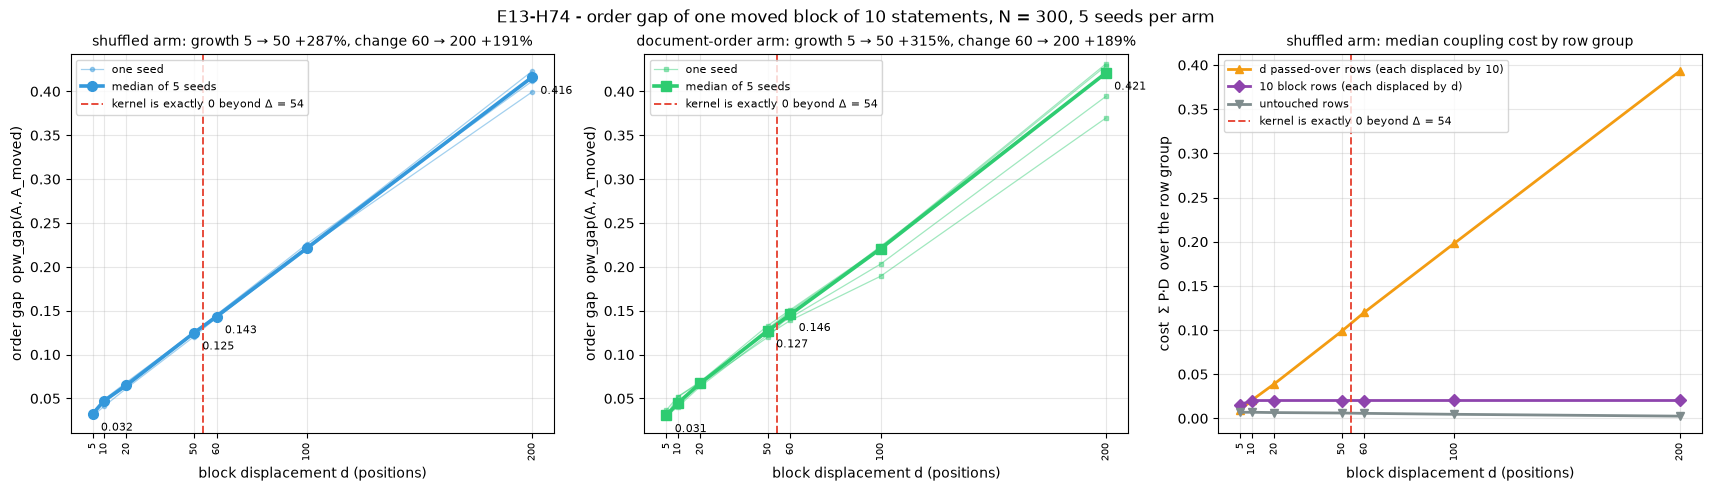

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8), constrained_layout=True)
xs = list(DISPLACEMENTS)

for ax, arm, colour, marker in ((axes[0], ARMS[0], C_SHUFFLED, "o"), (axes[1], ARMS[1], C_DOCORDER, "s")):
    for k, seed in enumerate(SEEDS):
        ax.plot(xs, [GAPS[arm][d][k] for d in xs], color=colour, lw=0.9, alpha=0.45, marker=marker, ms=3,
                label="one seed" if k == 0 else None)
    ax.plot(xs, [MEDIAN[arm][d] for d in xs], color=colour, lw=2.6, marker=marker, ms=7, label="median of 5 seeds")
    ax.axvline(WIDEST_ZERO_COST, color=C_EDGE, ls="--", lw=1.4, label=f"kernel is exactly 0 beyond Δ = {WIDEST_ZERO_COST}")
    for d in (*NEAR, *FAR):
        ax.annotate(f"{MEDIAN[arm][d]:.3f}", (d, MEDIAN[arm][d]), textcoords="offset points", xytext=(6, -12), fontsize=8)
    ax.set_title(f"{arm} arm: growth {NEAR[0]} → {NEAR[1]} {BAR[arm]['near_growth']:+.0%}, change {FAR[0]} → {FAR[1]} {BAR[arm]['far_change']:+.0%}", fontsize=10)
    ax.set_xlabel("block displacement d (positions)")
    ax.set_ylabel("order gap  opw_gap(A, A_moved)")
    ax.set_xticks(xs)
    ax.tick_params(axis="x", labelsize=7, rotation=90)
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8, loc="upper left")
axes[1].sharey(axes[0])

arm = ARMS[0]
ax = axes[2]
for key, label, colour, marker in (("cost_passed", "d passed-over rows (each displaced by 10)", C_PASSED, "^"),
                                   ("cost_block", "10 block rows (each displaced by d)", C_BLOCK, "D"),
                                   ("cost_untouched", "untouched rows", C_UNTOUCHED, "v")):
    ax.plot(xs, [MECH[arm][d][key] for d in xs], color=colour, lw=2.0, marker=marker, ms=6, label=label)
ax.axvline(WIDEST_ZERO_COST, color=C_EDGE, ls="--", lw=1.4, label=f"kernel is exactly 0 beyond Δ = {WIDEST_ZERO_COST}")
ax.set_title(f"{arm} arm: median coupling cost by row group", fontsize=10)
ax.set_xlabel("block displacement d (positions)")
ax.set_ylabel("cost  Σ P·D  over the row group")
ax.set_xticks(xs)
ax.tick_params(axis="x", labelsize=7, rotation=90)
ax.grid(alpha=0.3)
ax.legend(fontsize=8, loc="upper left")

fig.suptitle(f"E13-H74 - order gap of one moved block of {BLOCK} statements, N = {N}, 5 seeds per arm", fontsize=12)
plt.show()

## Guardrails

The standing guardrails, measured after the experiment. `V` counts the (gold, adversarial) pairs of the ibm
panel that the shipped `smd` ranks in the wrong order, out of 24. Byte identity compares the default-path
readings stored before the experiment with the same calls now. The tree hashes compare `src/`, `tests/` and
`docs/` before and after. The metric property is untouched because no code changed: `smd` stays the exact
metric and `opw_gap` stays what `distance.py` registers it as, a score and not a metric.

In [14]:
panel_after = np.array([smd(PANEL_EMB[label], PANEL_EMB[REFERENCE]) for label in NONREF])
guard_after = np.array([smd(gx, gy), opw_gap(gx, gy)])
trees_after = {rel: tree_sha256(rel) for rel in GUARD_TREES}
git_src_tests = subprocess.run(["git", "status", "--porcelain", "src", "tests"], cwd=ROOT, capture_output=True, text=True).stdout.strip()

dist = dict(zip(NONREF, panel_after.tolist()))
gold_d, adv_d = np.array([dist[l] for l in GOLD]), np.array([dist[l] for l in ADV])
V = int(sum(1 for g in gold_d for a in adv_d if g >= a))
V_TOTAL = len(GOLD) * len(ADV)
PANEL_ROW = {
    "V": V,
    "margin_pts": float(((1 - gold_d / SMD_MAX).min() - (1 - adv_d / SMD_MAX).max()) * 100),
    "dprime": float((adv_d.mean() - gold_d.mean()) / np.sqrt((gold_d.var() + adv_d.var()) / 2)),
    "R": float(adv_d.mean() / gold_d.mean()),
    "DR": float(np.concatenate([gold_d, adv_d]).std()),
}
NAIVE_REPRODUCED = bool(V == NAIVE_ROW["V"] and round(PANEL_ROW["margin_pts"], 2) == NAIVE_ROW["margin_pts"]
                        and round(PANEL_ROW["dprime"], 2) == NAIVE_ROW["dprime"]
                        and round(PANEL_ROW["R"], 3) == NAIVE_ROW["R"] and round(PANEL_ROW["DR"], 4) == NAIVE_ROW["DR"])

PANEL_IDENTICAL = bool(np.array_equal(panel_after, panel_before) and as_bytes(panel_after) == as_bytes(panel_before))
GUARD_IDENTICAL = bool(np.array_equal(guard_after, guard_before) and as_bytes(guard_after) == as_bytes(guard_before))
TREES_UNCHANGED = {rel: trees_after[rel] == trees_before[rel] for rel in GUARD_TREES}

t = Table(title="Guardrails", header_style="bold cyan")
for c in ("guardrail", "reading", "state"):
    t.add_column(c)
t.add_row("V - content ordinality", f"{V}/{V_TOTAL} violations", "hold" if V == 0 else "BREACH")
t.add_row("naive panel row", f"margin {PANEL_ROW['margin_pts']:+.2f} pts, d' {PANEL_ROW['dprime']:.2f}, R {PANEL_ROW['R']:.3f}, DR {PANEL_ROW['DR']:.4f} "
          f"(primer: +{NAIVE_ROW['margin_pts']}, {NAIVE_ROW['dprime']}, {NAIVE_ROW['R']:.3f}, {NAIVE_ROW['DR']})", "reproduced" if NAIVE_REPRODUCED else "DIFFERS")
t.add_row("panel smd, 10 distances", "np.array_equal and byte compare, before vs after", "hold" if PANEL_IDENTICAL else "BREACH")
t.add_row(f"default path {GUARD_PAIR}", f"smd {float(guard_after[0])!r}, order_gap {float(guard_after[1])!r}: np.array_equal and byte compare", "hold" if GUARD_IDENTICAL else "BREACH")
for rel in GUARD_TREES:
    t.add_row(f"{rel}/ tree sha256", f"{trees_before[rel][:16]} → {trees_after[rel][:16]}", "hold" if TREES_UNCHANGED[rel] else "BREACH")
t.add_row("git status src tests", git_src_tests or "(clean)", "hold" if not git_src_tests else "BREACH")
t.add_row("metric property", "no code changed: smd exact metric, opw_gap a score (not a metric)", "hold")
console.print(t)

                                                                Guardrails                                                                
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┓
┃ guardrail                       ┃ reading                                                                                 ┃ state      ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━┩
│ V - content ordinality          │ 0/24 violations                                                                         │ hold       │
│ naive panel row                 │ margin +4.71 pts, d' 4.68, R 1.670, DR 0.0873 (primer: +4.71, 4.68, 1.670, 0.0873)      │ reproduced │
│ panel smd, 10 distances         │ np.array_equal and byte compare, before vs after                                        │ hold       │
│ default path ('gold', 'gold-2') │ smd 0.22648980232576527, order_gap 0.14508837947471193: np.array_equal and byte compare │ hold       │
│ src/ tree sha256                │ f0e13add3de29ff3 → f0e13add3de29ff3                                                     │ hold       │
│ tests/ tree sha256              │ 00ea6c7799307adb → 00ea6c7799307adb                                                     │ hold       │
│ docs/ tree sha256               │ 46241ace1c95a621 → 46241ace1c95a621                                                     │ hold       │
│ git status src tests            │ (clean)                                                                                 │ hold       │
│ metric property                 │ no code changed: smd exact metric, opw_gap a score (not a metric)                       │ hold       │
└─────────────────────────────────┴─────────────────────────────────────────────────────────────────────────────────────────┴────────────┘

## Save - metrics

Every measured number, the bar readings and the guardrail readings, written to
`reports/E13-H74-order-kernel-reach-metrics.json` and printed in full.

In [15]:
def r6(value: float) -> float:
    """Round a reading to 6 decimals for the metrics file."""
    return round(float(value), 6)


metrics = {
    "id": "E13-H74",
    "slug": "order-kernel-reach",
    "encoder": "openvino INT8 mmBERT (CPU)",
    "docdistance_version": docdistance.__version__,
    "pot_version": ot.__version__,
    "seed": SEED,
    "constants": {"lambda1": OPW_LAMBDA1, "lambda2": OPW_LAMBDA2, "sigma": OPW_SIGMA},
    "pool": {
        "documents": [{"document": name, "statements": n_all, "unique_added": n_new} for name, n_all, n_new in doc_rows],
        "unique_statements": POOL_SIZE,
        "largest_ground_cost": r6(POOL_COST_MAX),
        "length_run": N,
        "length_600_feasible": LONG_FEASIBLE,
        "structure_threshold": STRUCTURE_THRESHOLD,
    },
    "kill_gate": {
        "kernel": f"K of _opw_plan, N = M = {N}, shipped constants",
        "offset": GATE_OFFSET,
        "entries_per_kernel": GATE_ENTRIES,
        "nonzero_at_offset_zero_cost": GATE_NONZERO_ZERO_COST,
        "nonzero_at_offset_measured": GATE_NONZERO_MEASURED,
        "measured_kernels": n_kernels,
        "shifted_log_k_at_offset_zero_cost": round(GATE_LOG_ZERO_COST, 2),
        "shifted_log_k_at_offset_measured_max": round(measured_max_log[GATE_OFFSET], 2),
        "shifted_log_k_at_offset_upper_bound": round(GATE_LOG_BOUND, 2),
        "log_smallest_positive_float64": round(LOG_SMALLEST_FLOAT, 2),
        "widest_nonzero_offset_zero_cost": WIDEST_ZERO_COST,
        "widest_nonzero_offset_measured": measured_widest,
        "passed": KILL_GATE_PASSED,
    },
    "harness": {
        "replica_plan_equals_shipped_plan": replica_identical,
        "ground_cost_matrices_checked": n_kernels,
        "row_group_split_equals_shipped_gap": SPLIT_EXACT,
        "block_moves_verified": bool(moves_ok),
    },
    "sweep": {
        "block": BLOCK,
        "displacements": list(DISPLACEMENTS),
        "seeds": list(SEEDS),
        "solves": sweep_df.height,
        "smd_largest": r6(SMD_MAX_SEEN),
        "arms": {
            arm: {
                "block_start_per_seed": [SEQUENCES[(arm, seed)][1] for seed in SEEDS],
                "adjacent_ground_cost_per_seed": [round(ADJ_COST[(arm, seed)], 4) for seed in SEEDS],
                "gap_per_seed": {str(d): [round(g, 5) for g in GAPS[arm][d]] for d in ALL_D},
                "gap_median": {str(d): round(MEDIAN[arm][d], 5) for d in ALL_D},
                "structure_closeness_of_median": {str(d): round(CLOSENESS[arm][d], 4) for d in ALL_D},
                "shipped_verdict_of_median": {str(d): verdict(CLOSENESS[arm][d], STRUCTURE_THRESHOLD) for d in ALL_D},
            }
            for arm in ARMS
        },
    },
    "acceptance": {
        "bar": "Confirmed iff the median order gap grows >= 20% between displacement 5 and 50 AND changes <= 5% between 60 and 200; Refuted if it still grows >= 20% between 60 and 200",
        "primary_arm": ARMS[0],
        "readings": {
            arm: {
                "growth_5_to_50_pct": round(BAR[arm]["near_growth"] * 100, 1),
                "change_60_to_200_pct": round(BAR[arm]["far_change"] * 100, 1),
                "growth_5_to_50_pct_per_seed": [round(v * 100, 1) for v in BAR[arm]["near_per_seed"]],
                "change_60_to_200_pct_per_seed": [round(v * 100, 1) for v in BAR[arm]["far_per_seed"]],
            }
            for arm in ARMS
        },
        "near_growth_met": NEAR_MET,
        "far_flat_met": FAR_FLAT_MET,
        "confirmed": CONFIRMED,
        "refuted": REFUTED,
        "control_agrees": CONTROL_AGREES,
        "sequences_growing_60_to_200": f"{SEEDS_FAR_GROWING}/{len(ARMS) * len(SEEDS)}",
        "verdict": VERDICT,
    },
    "mechanism": {
        "row_group_medians": {
            arm: {
                str(d): {
                    "displaced_statements": d + BLOCK,
                    "block_rows": round(MECH[arm][d]["cost_block"], 5),
                    "passed_over_rows": round(MECH[arm][d]["cost_passed"], 5),
                    "untouched_rows": round(MECH[arm][d]["cost_untouched"], 5),
                    "own_statement_mass_block_rows": round(MECH[arm][d]["own_block"], 4),
                    "own_statement_mass_passed_over_rows": round(MECH[arm][d]["own_passed"], 4),
                    "cost_per_displaced_statement": round(MECH[arm][d]["cost_per_displaced"], 4),
                }
                for d in DISPLACEMENTS
            }
            for arm in ARMS
        },
        "block_rows_change_pct": {arm: {k: round(v * 100, 2) for k, v in BLOCK_ROWS[arm].items()} for arm in ARMS},
        "passed_over_share_of_growth_60_to_200_pct": {arm: round(PASSED_SHARE[arm] * 100, 1) for arm in ARMS},
        "own_statement_mass_block_rows_max_d_ge_10": float(f"{OWN_BLOCK_MAX_FAR:.2e}"),
        "own_statement_mass_passed_over_rows_max": float(f"{OWN_PASSED_MAX:.2e}"),
        "linear_fit_gap_vs_displaced_fraction": {arm: {k: round(v, 4) for k, v in FIT[arm].items()} for arm in ARMS},
        "position_penalty": {str(delta): round(PENALTY[delta], 4) for delta in PENALTY_ROWS},
        "cost_reach_positions": COST_REACH,
        "float64_support_edge_positions": WIDEST_ZERO_COST,
    },
    "guardrails": {
        "V": f"{V}/{V_TOTAL}",
        "panel_row": {"margin_pts": round(PANEL_ROW["margin_pts"], 2), "dprime": round(PANEL_ROW["dprime"], 2),
                      "R": round(PANEL_ROW["R"], 3), "DR": round(PANEL_ROW["DR"], 4)},
        "naive_row_reproduced": NAIVE_REPRODUCED,
        "panel_smd_byte_identical": PANEL_IDENTICAL,
        "default_path_byte_identical": GUARD_IDENTICAL,
        "tree_sha256_unchanged": TREES_UNCHANGED,
        "git_status_src_tests": git_src_tests or "clean",
        "metric_property": "unchanged - no code changed; smd exact metric, opw_gap a score (not a metric)",
    },
}
METRICS_OUT.write_text(json.dumps(metrics, indent=2, ensure_ascii=False) + "\n")
print(f"wrote {METRICS_OUT.relative_to(ROOT)} ({METRICS_OUT.stat().st_size} bytes)")
print(json.dumps(metrics, indent=2, ensure_ascii=False))

wrote reports/E13-H74-order-kernel-reach-metrics.json (15064 bytes)
{
  "id": "E13-H74",
  "slug": "order-kernel-reach",
  "encoder": "openvino INT8 mmBERT (CPU)",
  "docdistance_version": "1.1.5",
  "pot_version": "0.9.6.post1",
  "seed": 42,
  "constants": {
    "lambda1": 50.0,
    "lambda2": 0.1,
    "sigma": 1.0
  },
  "pool": {
    "documents": [
      {
        "document": "01-statements.parquet",
        "statements": 163,
        "unique_added": 158
      },
      {
        "document": "ibm source article",
        "statements": 70,
        "unique_added": 52
      },
      {
        "document": "wergeland source article",
        "statements": 52,
        "unique_added": 50
      },
      {
        "document": "summary gold",
        "statements": 11,
        "unique_added": 11
      },
      {
        "document": "summary gold-2",
        "statements": 13,
        "unique_added": 13
      },
      {
        "document": "summary v1",
        "statements": 12,
        "unique_

## Conclusions

**Verdict: Refuted.** The kernel premise holds and the predicted saturation does not occur. On 300-statement sequences the median order gap of the primary (shuffled) arm grows `+190.5%` between displacement 60 and 200 (`0.14324 → 0.41615`). The bar allows a change of at most 5% and registers a refutation at 20% growth.

**Kill-gate - passed**

- Entries of `K` at `|i − j| = 60` for `N = M = 300`: `0` non-zero of `480` at zero ground cost, `0` of `38400` over the 80 ground-cost matrices this experiment solves
- Shifted `log K` at offset 60 reads `-919.23` at zero ground cost and at most `-899.23` for any ground cost up to 2; float64 `exp` returns `0.0` at `-745.14`
- The widest offset that holds a non-zero entry is `54` at zero ground cost and `53` with the measured ground costs, which matches the registered "about 54 positions"
- The replica kernel reproduces the shipped `opw_plan` bit for bit on all 80 matrices, so the gate read the shipped kernel

**Registered bar - first clause met, second clause falsified**

- `d = 5 → 50`: `+286.6%` in the shuffled arm (`0.03228 → 0.12482`), `+315.1%` in the document-order arm (`0.03064 → 0.12718`); the bar asks for at least 20%
- `d = 60 → 200`: `+190.5%` in the shuffled arm, `+188.7%` in the document-order arm (`0.14584 → 0.42098`); the bar asks for at most 5%
- Each of the 10 sequences grows between `+166.0%` and `+193.1%` from 60 to 200, so the reading does not depend on one seed
- The document-order control gives the same reading on both clauses, so the result is not an artefact of shuffling the pool

**Mechanism - the gap counts displaced statements, not the distance moved**

- A block of 10 moved by `d` positions shifts the `d` statements it passes over by 10 positions each, so `d + 10` statements are out of place
- The order gap is linear in that count: `gap = 0.5833 × (d + 10)/300 + 0.0063` with `R² 0.9990` in the shuffled arm; slope `0.5717`, intercept `0.0081`, `R² 0.9912` in the document-order arm
- The growth from 60 to 200 comes from the passed-over rows: their cost goes `0.11992 → 0.39295`, which is `100.0%` of the median gap growth in the shuffled arm
- The 10 block rows cost `0.02023` at `d = 10` and `0.02027` at `d = 200`, a change of `+0.19%`. The cost of the block's own rows is constant from 10 positions on, a displacement well below the 54-position float64 support
- The coupling places `0.1227` of a block row's mass on the row's own statement at `d = 5` and at most `2.58e-04` from `d = 10`. Passed-over rows, displaced by 10 positions, receive at most `1.10e-05`
- Cause: the kernel charges `pen(Δ)` per unit of mass moved `Δ` positions - `0.6389` at 5, `1.2522` at 7, `1.6355` at 8, `2.5555` at 10. The largest ground cost between any two pooled statements is `1.3356`. From 8 positions on, matching a displaced statement to itself costs more in the linear part of the Sinkhorn objective than matching it to any statement near its old position
- A displaced statement therefore pays the ground cost to an unrelated statement near its old position: `0.5895` to `0.6015` per displaced statement for `d ≥ 10` in the shuffled arm, where adjacent statements cost `0.6195` to `0.6464`
- The float64 underflow at 54 positions exists and has no effect on the reading: the coupling stops reaching a statement's counterpart below 10 positions, a much smaller displacement than the one at which the kernel value becomes zero
- The numeric pattern of the prediction appears on the block rows alone (`+31.1%` from 5 to 50, `+0.01%` from 60 to 200), with the constant part starting at 10 positions and not at 54

**Meaning for the shipped read**

- For a statement displaced by 8 positions or more, `opw_gap` does not grow with the distance moved. It reads the fraction of statements that are out of place, multiplied by the ground cost between unrelated statements
- `structure_closeness` of the shuffled medians reads `0.9117` at `d = 50` and `0.8987` at `d = 60`: one block of 10 moved by 60 positions in a 300-statement document reads below `STRUCTURE_THRESHOLD = 0.90`. At `d = 200` it reads `0.7057`, the level that `distance.py:33-35` records for the full-scramble rung of the E11 ibm ladder (`0.706`)
- The unmoved pair `opw_gap(A, A)` reads `0.00655` in the shuffled arm and `0.00995` in the document-order arm, not 0. The entropic coupling places a small share of each row's mass on adjacent statements

**Guardrails - all hold**

- `V = 0/24`; the panel row reproduces the primer's naive row (margin `+4.71` pts, d' `4.68`, R `1.670`, DR `0.0873`)
- Default-path `smd` and `order_gap` on `(gold, gold-2)` are byte-identical before and after, and so are the 10 panel distances
- `src/`, `tests/` and `docs/` tree hashes are unchanged and `git status src tests` is clean
- No code changed: `smd` stays the exact metric, `opw_gap` stays a score and not a metric

**Limits**

- The pool holds `372` unique statements, so the registered 600-statement length was not run
- One block start per sequence, drawn from positions 0 to 90, and forward moves only
- Each sequence is a concatenation of pooled statements and short documents, not one long authored document
- `A_moved` holds the same statements as `A`, so `smd` reads at most `0.000302` (float noise of the ground cost) and the order gap equals the OPW cost. A pair that also differs in content is not measured here
- The position at which `pen(Δ)` exceeds the ground cost depends on the ground-cost scale of the encoder; on this pool the largest ground cost is `1.3356`